# GOT-OCR 2.0 — OCR généraliste (transformers natif)

GOT-OCR 2.0 (StepFun) est un modèle OCR de bout en bout : un encodeur visuel et un petit décodeur de langage
qui lisent directement la page. Il est intégré nativement dans `transformers` (pas de `trust_remote_code`).

| | |
|---|---|
| Modèle | [stepfun-ai/GOT-OCR-2.0-hf](https://huggingface.co/stepfun-ai/GOT-OCR-2.0-hf) |
| Licence | Apache-2.0 |
| Taille | ≈ 580 M paramètres |
| Matériel | CPU possible (lent), GPU recommandé |
| Sortie | texte brut (ou Markdown/LaTeX avec `format=True`) |
| PDF | pages rastérisées avec `pypdfium2` (fonction commune `load_document`) |

Aucune clé d'API ni token HuggingFace n'est nécessaire : les poids publics sont téléchargés au premier lancement
(dans `~/.cache/huggingface`). Le notebook se lance depuis le dossier `hf_ocr_notebooks/` (il importe `ocr_common.py`).

In [2]:
%pip install -q transformers accelerate pypdfium2 pillow pandas rapidfuzz

^C
ERROR: Operation cancelled by user
Note: you may need to restart the kernel to use updated packages.


## 1. Préparation

In [4]:
import time
from pathlib import Path

import torch
from IPython.display import display

import ocr_common as oc

FILES = oc.make_test_set()          # 6 images + 1 PDF de 2 pages, avec vérité terrain
FILES = oc.list_inputs()            # + vos fichiers déposés dans data/custom/
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Matériel :", oc.hardware())
print(f"{len(FILES)} fichiers :", ", ".join(f.name for f in FILES))

ModuleNotFoundError: No module named 'pandas'

## 2. Chargement du modèle

In [3]:
t0 = time.perf_counter()
from transformers import AutoModelForImageTextToText, AutoProcessor

REPO = "stepfun-ai/GOT-OCR-2.0-hf"
DTYPE = torch.bfloat16 if DEVICE == "cuda" else torch.float32
processor = AutoProcessor.from_pretrained(REPO)
model = AutoModelForImageTextToText.from_pretrained(REPO, dtype=DTYPE, device_map=DEVICE).eval()
LOAD_S = time.perf_counter() - t0
print(f"Modèle chargé en {LOAD_S:.1f}s sur {DEVICE}")

/tmp/claude-1000/-claude-agent/2317e256-75e4-4892-9854-2f7a544fcb4f/scratchpad/hfenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/471 [00:00<01:24,  5.55it/s]

Loading weights:  47%|████▋     | 221/471 [00:00<00:00, 953.92it/s]

Loading weights:  73%|███████▎  | 345/471 [00:00<00:00, 913.96it/s]

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 1018.96it/s]

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 887.55it/s] 

Modèle chargé en 109.8s sur cpu


## 3. Fonction d'extraction


`format=True` produit du Markdown/LaTeX (utile pour tableaux et formules) ; `False` donne du texte brut.
Pour les pages très denses, `crop_to_patches=True` découpe l'image en tuiles (plus précis, plus lent).

In [4]:
FORMAT = False
CROP_TO_PATCHES = False


@torch.inference_mode()
def extract(image, max_new_tokens=4096):
    inputs = processor(image, return_tensors="pt", format=FORMAT, crop_to_patches=CROP_TO_PATCHES,
                       max_patches=6).to(DEVICE, DTYPE)
    out = model.generate(**inputs, do_sample=False, tokenizer=processor.tokenizer,
                         stop_strings="<|im_end|>", max_new_tokens=max_new_tokens)
    return processor.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

## 4. Démonstration sur une image et sur un PDF

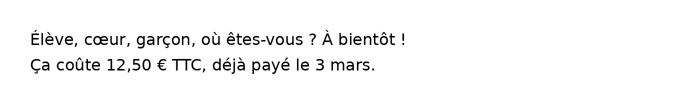

In [5]:
img_path = oc.SYNTH_DIR / "accents_fr.png"
img = oc.load_document(img_path)[0]
display(img.resize((img.width // 2, img.height // 2)))
t = time.perf_counter()
print(extract(img))
print(f"\n({time.perf_counter() - t:.1f}s)")

In [ ]:
pdf_path = oc.SYNTH_DIR / "rapport_2_pages.pdf"
for i, page in enumerate(oc.load_document(pdf_path), 1):
    t = time.perf_counter()
    text = extract(page)
    print(f"--- page {i} ({time.perf_counter() - t:.1f}s)\n{text}\n")

## 5. Benchmark sur le jeu de test

Temps par page et précision (CER / WER) sur tous les fichiers. Le premier appel inclut un éventuel temps de compilation/« chauffe ».
Les textes extraits sont enregistrés dans `results/<modèle>/` et les mesures dans `results/<modèle>.csv`
(utilisées par le notebook `00_comparaison.ipynb`).

In [ ]:
MODEL_NAME = "GOT-OCR-2.0"
df = oc.run_benchmark(extract, MODEL_NAME, FILES)
oc.save_meta(MODEL_NAME, repo="stepfun-ai/GOT-OCR-2.0-hf", load_s=LOAD_S, device=DEVICE)
display(oc.summarize(df).to_frame(MODEL_NAME))

In [ ]:
display(df[[c for c in ("file", "type", "pages", "s_per_page", "cer", "wer", "error") if c in df]].round(3))
oc.show_comparison(df, n=3)

## 6. Utiliser le modèle sur vos propres fichiers

Remplacez le chemin ci-dessous par une image ou un PDF ; le texte est enregistré à côté du fichier (`.ocr.txt`).

In [ ]:
def extract_file(path, dpi=200, max_pages=None):
    path = Path(path)
    pages = oc.load_document(path, dpi=dpi, max_pages=max_pages)
    text = "\n\n".join(extract(p) for p in pages)
    path.with_suffix(".ocr.txt").write_text(text, encoding="utf-8")
    return text


# print(extract_file("data/custom/mon_document.pdf"))